In [10]:
import h5py
import pandas as pd
import plotly.express as px
import numpy as np
import matplotlib.pyplot as plt

# for a given matrix type and a given implementation, plot boxplots of the componentwise relative errors for each dimension
def plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, ax):

    # query metadata df for ids of desired matrices
    filtered_ids    = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] ==    impl)].sort_values(by="m")["matrix_id"]
    filtered_gt_ids = metadata_df[(metadata_df["input_type"] == input_type) & (metadata_df["matrix_name"] == gt_impl)].sort_values(by="m")["matrix_id"]

    # calculate componentwise_unsigned_relative_errors
    # note the potential divide-by-zero issue here
    dims = []
    unsigned_relative_errors = []
    for mat_id, gt_mat_id in zip(filtered_ids, filtered_gt_ids):
        
        mat = matrices_dict[f"{mat_id}"][:]
        gt_mat = matrices_dict[f"{gt_mat_id}"][:]
        
        dims.append(mat.shape[0])
        
        vals = mat.flatten()
        gt_vals = gt_mat.flatten()
        unsigned_relative_errors.append(abs((vals - gt_vals) / gt_vals))
    
    # plot
    ax.boxplot(unsigned_relative_errors, labels=dims)
    ax.set_title(f"{impl.split('-')[0]}")
    ax.set_yscale("log")
    ax.tick_params("x", rotation=45)

In [2]:
h5_file = h5py.File("grading_dgemm.h5", "a")

matrices_dict = h5_file["matrices"]

metadata_df = pd.DataFrame(h5_file["metadata"][:])
metadata_df["matrix_name"] = metadata_df["matrix_name"].str.decode("utf-8")
metadata_df["input_type"] = metadata_df["input_type"].str.decode("utf-8")
metadata_df["matrix_name"].unique()

array(['A', 'B', 'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
       'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
       'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
       'CUBLAS-12.9-unknown-unknown-NVCC8.0',
       'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
       'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
       'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3'],
      dtype=object)

# U(0,1) w/ naive-triple-loop reference _in FP64 precision_

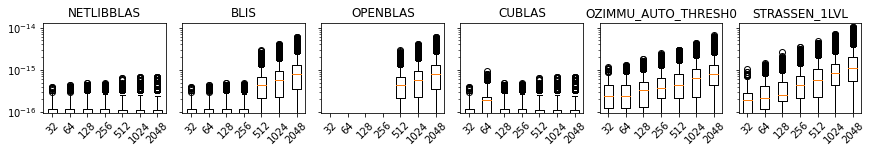

In [13]:
gt_impl = "NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3"
input_type = "U_0_1"

impls = [
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    #'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
]

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=True, constrained_layout=True)

for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

# U(0,1) w/ naive-triple-loop reference _in FP80 precision_

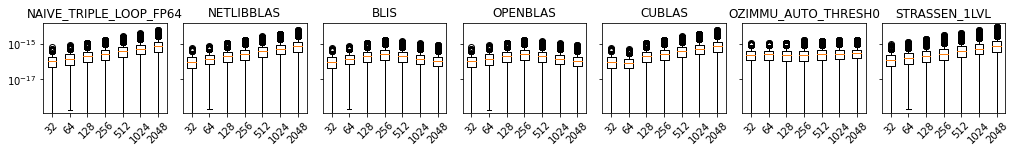

In [14]:
gt_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3"
input_type = "U_0_1"

impls = [
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
]

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=True, constrained_layout=True)

for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

# U(-1,1) w/ naive-triple-loop reference _in FP64 precision_

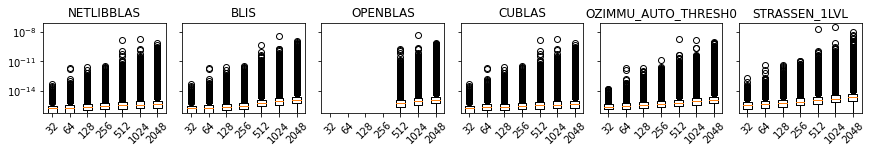

In [15]:
gt_impl = "NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3"
input_type = "U_-1_1"

impls = [
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    #'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
]

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=True, constrained_layout=True)

for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

# U(-1,1) w/ naive-triple-loop reference _in FP80 precision_

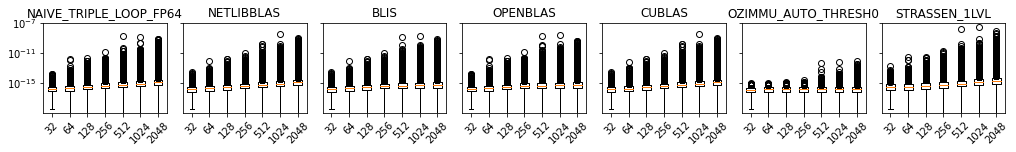

In [16]:
gt_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3"
input_type = "U_-1_1"

impls = [
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
]

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=True, constrained_layout=True)

for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])

# test3 w/ naive-triple-loop reference _in FP80 precision_

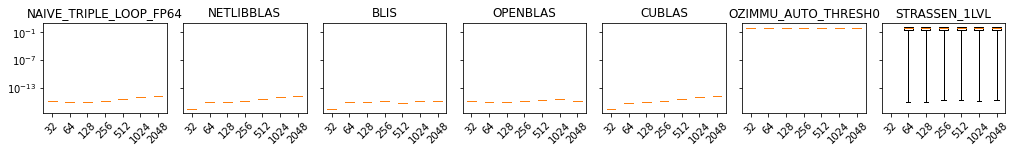

In [17]:
gt_impl = "NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3"
input_type = "test3"

impls = [
    #'NAIVE_TRIPLE_LOOP_EXTENDED_PRECISION-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NAIVE_TRIPLE_LOOP_FP64-89e4cab-GNU_13.2-O0-x86_64_zen3',
    'NETLIBBLAS-3.12.1-GNU_13.2-DEFAULT-x86_64_zen3',
    'BLIS-2.0-GNU_13.2-DEFAULT-x86_64_zen3',
    'OPENBLAS-0.3.30-GNU_13.2-DEFAULT-x86_64_zen3',
    'CUBLAS-12.9-unknown-unknown-NVCC8.0',
    'OZIMMU_AUTO_THRESH0-08eea92-GNU_13.2+NVCC_12.9-DEFAULT-NVCC8.0',
    'STRASSEN_1LVL-649b52d-GNU_13.2-O0-x86_64_zen3',
]

fig, axs = plt.subplots(1,len(impls), figsize=(len(impls)*2,2), sharey=True, constrained_layout=True)

for subplot_idx, impl in enumerate(impls):
    plot_all_componentwise_unsigned_relative_error_vs_dim(input_type, impl, gt_impl, metadata_df, matrices_dict, axs[subplot_idx])